In [1]:
from cloudvolume import CloudVolume

path = (
    "file:///volume_4/research/seongbong/align/"
    "cerebellum_align_verified/normalized_full/img/img_norm"
)

cv = CloudVolume(path, mip=8, progress=False)

print("MIP8 chunk:", cv.chunk_size)

MIP8 chunk: [512 512   1]


In [5]:
from pathlib import Path
import json
import shutil

base = Path(
    "/volume_4/research/seongbong/align/cerebellum_align_verified2/img_raw"
)

info_path = base / "info"

with open(info_path) as f:
    info = json.load(f)

# metadata 백업
shutil.copy2(info_path, base / "info.backup")

for mip in [8, 7, 6, 5]:
    scale = info["scales"][mip]
    key = scale["key"]

    print(f"MIP{mip}: {key}")
    print("Before:", scale["chunk_sizes"])

    # 기존 chunk 파일이 있으면 중단
    scale_dir = base / key
    if scale_dir.exists() and any(scale_dir.iterdir()):
        raise RuntimeError(
            f"{scale_dir}에 기존 데이터가 있습니다. "
            "기존 데이터를 백업하거나 별도 출력 경로를 사용하세요."
        )

    scale["chunk_sizes"] = [[512, 512, 1]]

    print("After:", scale["chunk_sizes"])

with open(info_path, "w") as f:
    json.dump(info, f, indent=2)

MIP8: 1024_1024_40
Before: [[64, 64, 1]]


RuntimeError: /volume_4/research/seongbong/align/cerebellum_align_verified2/img_raw/1024_1024_40에 기존 데이터가 있습니다. 기존 데이터를 백업하거나 별도 출력 경로를 사용하세요.

In [2]:
import json
from pathlib import Path

base = Path(
    "/volume_4/research/seongbong/align/cerebellum_align_verified2/img_raw"
)

with open(base / "info") as f:
    info = json.load(f)

for mip in [8, 7, 6, 5]:
    scale = info["scales"][mip]
    print(
        f"MIP {mip}:",
        "size =", scale["size"],
        "chunk =", scale["chunk_sizes"],
        "key =", scale["key"]
    )

MIP 8: size = [975, 900, 1200] chunk = [[64, 64, 1]] key = 1024_1024_40
MIP 7: size = [1950, 1800, 1200] chunk = [[512, 512, 1]] key = 512_512_40
MIP 6: size = [3900, 3600, 1200] chunk = [[512, 512, 1]] key = 256_256_40
MIP 5: size = [7800, 7200, 1200] chunk = [[512, 512, 1]] key = 128_128_40


In [3]:

from cloudvolume import CloudVolume
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm
import numpy as np
import threading

SRC_URL = "https://bossdb-open-data.s3.amazonaws.com/nguyen_thomas2022/cb2/em"
DST_URL = "file:///volume_4/research/seongbong/align/cerebellum_align_verified2/img_raw"

Z_START = 366
Z_END = 701  # exclusive: z=700까지 포함

MAX_WORKERS = 8

# Worker마다 별도 CloudVolume 객체 사용
thread_local = threading.local()


def get_volumes(mip):
    if getattr(thread_local, "mip", None) != mip:
        thread_local.src = CloudVolume(
            SRC_URL,
            mip=mip,
            progress=False,
            fill_missing=False
        )
        thread_local.dst = CloudVolume(
            DST_URL,
            mip=mip,
            progress=False,
            compress=False
        )
        thread_local.mip = mip

    return thread_local.src, thread_local.dst


def download_tile(task):
    mip, x, xe, y, ye, z_batch, ze = task

    src, dst = get_volumes(mip)

    # S3에서 Z chunk 단위로 다운로드
    block = np.asarray(
        src[x:xe, y:ye, z_batch:ze, :]
    )

    # 필요한 section만 저장
    zs = max(z_batch, Z_START)
    zend = min(ze, Z_END)

    for z in range(zs, zend):
        k = z - z_batch

        dst[x:xe, y:ye, z:z+1, :] = (
            block[:, :, k:k+1, :]
        )

    return len(range(zs, zend))


for mip in [8, 7,6,5]:

    src = CloudVolume(
        SRC_URL,
        mip=mip,
        progress=False,
        fill_missing=False
    )

    dst = CloudVolume(
        DST_URL,
        mip=mip,
        progress=False,
        compress=False
    )

    x0, y0 = map(int, src.bounds.minpt[:2])
    x1, y1 = map(int, src.bounds.maxpt[:2])

    cx, cy, _ = map(int, dst.chunk_size)
    src_cz = int(src.chunk_size[2])

    src_zmin = int(src.bounds.minpt.z)
    src_zmax = int(src.bounds.maxpt.z)

    if not (src_zmin <= Z_START < Z_END <= src_zmax):
        raise ValueError("Requested Z range exceeds source bounds")

    # 병렬 쓰기 시 목적지 chunk가 겹치지 않도록 확인
    ox, oy = map(int, dst.bounds.minpt[:2])

    if (x0 - ox) % cx or (y0 - oy) % cy:
        raise ValueError(
            "XY tile boundaries are not aligned to destination chunks"
        )

    z0 = src_zmin + (
        (Z_START - src_zmin) // src_cz
    ) * src_cz

    print(f"\nMIP {mip}")
    print("Source chunk:", src.chunk_size)
    print("Destination chunk:", dst.chunk_size)
    print("Workers:", MAX_WORKERS)

    with ThreadPoolExecutor(
        max_workers=MAX_WORKERS
    ) as executor:

        for z_batch in range(z0, Z_END, src_cz):

            ze = min(
                z_batch + src_cz,
                src_zmax,
                Z_END
            )

            tasks = [
                (mip, x, min(x + cx, x1),
                 y, min(y + cy, y1),
                 z_batch, ze)
                for y in range(y0, y1, cy)
                for x in range(x0, x1, cx)
            ]

            futures = [
                executor.submit(download_tile, task)
                for task in tasks
            ]

            for future in tqdm(
                as_completed(futures),
                total=len(futures),
                desc=f"MIP{mip} z={z_batch}"
            ):
                future.result()

    print(f"MIP{mip} completed")



MIP 8
Source chunk: [512 512  25]
Destination chunk: [64 64  1]
Workers: 8


MIP8 z=350:   0%|          | 0/240 [00:00<?, ?it/s]

MIP8 z=375:   0%|          | 0/240 [00:00<?, ?it/s]

MIP8 z=400:   0%|          | 0/240 [00:00<?, ?it/s]

MIP8 z=425:   0%|          | 0/240 [00:00<?, ?it/s]

...

MIP5 z=625:   0%|          | 0/240 [00:00<?, ?it/s]

MIP5 z=650:   0%|          | 0/240 [00:00<?, ?it/s]

MIP5 z=675:   0%|          | 0/240 [00:00<?, ?it/s]

MIP5 z=700:   0%|          | 0/240 [00:00<?, ?it/s]

MIP5 completed


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import numpy as np
import torch
from cloudvolume import CloudVolume

cv = CloudVolume(
    "file:///volume_4/research/seongbong/align/"
    "cerebellum_align_verified2/img_masked",
    mip=8,
    progress=False,
)

def read_image(x0, x1, y0, y1, z):
    return np.asarray(
        cv[x0:x1, y0:y1, z:z+1]
    )[:, :, 0, 0].T.astype(np.float32)

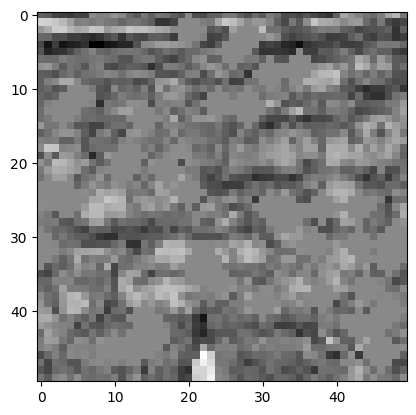

In [16]:

img = read_image(500, 550, 500, 550, 501)
fig,ax = plt.subplots(1,1)
ax.imshow(img, cmap="gray")